# GPT-2 em português × Machado de Assis
**Fine-tuning, avaliação experimental e demonstração**

| Seção | Regra do trabalho |
|---|---|
| 0. Ambiente | preparação |
| 1. Visão geral do experimento | ponte com a fundamentação/arquitetura |
| 2. Dados | 3. Implementação funcional |
| 3. Treino | 3. Implementação funcional |
| 4. Avaliação experimental | 4. Avaliação experimental |
| 5. Demonstração | 5. Demonstração (interface ao vivo) |

**Pergunta do experimento:** o que o fine-tuning em ~1 MB de texto muda no comportamento de um GPT-2 que já sabe português?

## 0. Ambiente

In [1]:
import platform, torch, transformers
print("Python      :", platform.python_version())
print("PyTorch     :", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA        :", torch.cuda.is_available())
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print("GPU         :", props.name, f"({props.total_memory / 1e9:.1f} GB)")

Python      : 3.12.13
PyTorch     : 2.8.0+cu126
Transformers: 5.20.2
CUDA        : True
GPU         : NVIDIA GeForce RTX 3050 6GB Laptop GPU (6.4 GB)


## 1. Visão geral do experimento

- **Modelo base:** `pierreguillou/gpt2-small-portuguese` (GPT-2 small, 124M parâmetros).
- **Treino:** causal language modeling (prever o próximo token), laço escrito à mão em PyTorch.
- **Comparação:** *mesmo* tokenizer nos dois modelos, então perplexidades são diretamente comparáveis.
- **Geração:** amostragem própria (temperatura, top-k, top-p, penalidade de repetição, cache KV) em `generate.py`.

## 2. Dados

Os livros vêm do Project Gutenberg (domínio público). Se o download automático falhar, baixe o *Plain Text UTF-8* de cada ebook e salve em `data/raw/` com os nomes de `config.GUTENBERG_BOOKS` (ex.: `dom_casmurro.txt`). Qualquer `.txt` colocado em `data/raw/` também entra no corpus.

In [2]:
from machado_gpt.config import GUTENBERG_BOOKS, TrainConfig, BASE_MODEL
from machado_gpt.data import prepare_corpus, load_books

stats = prepare_corpus()   # baixa o que faltar em data/raw e limpa em data/processed

  dom_casmurro                           383,010 caracteres |   65,707 palavras
  memorias_posthumas_de_braz_cubas       368,544 caracteres |   61,537 palavras
  quincas_borba                          458,576 caracteres |   76,026 palavras


In [3]:
books = load_books()
nome = next(iter(books))
print(f"Trecho de '{nome}':\n")
print(books[nome][2000:2600])

Trecho de 'dom_casmurro':

ulo seu, poderá cuidar que a obra

é sua. Ha livros que apenas terão isso dos seus autores; alguns nem

tanto.

II.

Do livro.

Agora que expliquei o titulo, passo a escrever o livro. Antes disso,

porém, digamos os motivos que me põem a penna na mão.

Vivo só, com um creado. A casa em que moro é propria; fil-a

construir de proposito, levado de um desejo tão particular que me

vexa imprimil-o, mas vá lá. Um dia, ha bastantes annos, lembrou-me

reproduzir no Engenho Novo a casa em que me criei na antiga rua de

Matacavallos, dando-lhe o mesmo aspecto e economia daquella outra,

que desapparece


### Hiperparâmetros
Se aparecer `CUDA out of memory`, reduza `batch_size` para 2 e aumente `grad_accum_steps` para 8 (o batch efetivo continua o mesmo).

`holdout_book="quincas_borba"` deixa um livro **inteiro** fora do treino, usado só como conjunto de teste. Para o treino final com todos os livros, use `holdout_book=None`.

In [4]:
cfg = TrainConfig()
cfg

TrainConfig(block_size=256, batch_size=4, grad_accum_steps=4, epochs=4, lr=5e-05, weight_decay=0.01, warmup_ratio=0.06, max_grad_norm=1.0, eval_every=20, val_fraction=0.1, holdout_book='quincas_borba', gradient_checkpointing=True, seed=42)

## 3. Treino (fine-tuning)

O `train()` mede a loss de validação **antes de treinar** (passo 0, que é o desempenho do modelo original), treina por `epochs` épocas e salva em `checkpoints/machado-gpt2/best` o checkpoint com menor loss de validação. Isso protege contra overfitting.

In [5]:
from machado_gpt.train import train

result = train(cfg)

W1026 18:15:44.367000 62508 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: pierreguillou/gpt2-small-portuguese
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


treino: 801 blocos | validação: 88 blocos | teste (quincas_borba): 536 blocos
200 passos de otimizador (50/época) | batch efetivo = 16 blocos de 256 tokens
dispositivo: cuda | precisão mista: torch.bfloat16


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


...

  [passo  180] loss treino 3.8720 | loss val 3.8346 | ppl val 46.27


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  [passo  200] loss treino 3.8596 | loss val 3.8339 | ppl val 46.24


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Pronto em 303.5s | ppl val: 111.6 -> 46.2 | melhor modelo em C:\Users\diego\machado-gpt\checkpoints\machado-gpt2\best


,step,epoch,train_loss,val_loss,val_ppl,lr,elapsed_s
0,0,0,NaN,4.7154,111.6498,0.0,4.3
1,20,1,4.7126,4.2951,73.3394,0.0,32.2
2,40,1,4.4103,4.1066,60.7420,0.0,63.8
3,60,2,4.2241,3.9979,54.4862,0.0,94.8
4,80,2,4.1012,3.9321,51.0128,0.0,123.2
5,100,2,4.0340,3.8858,48.7053,0.0,155.1
6,120,3,3.9492,3.8629,47.6028,0.0,186.7
7,140,3,3.9053,3.8459,46.7994,0.0,217.4
8,160,4,3.8958,3.8386,46.4614,0.0,245.7
9,180,4,3.8720,3.8346,46.2742,0.0,274.0


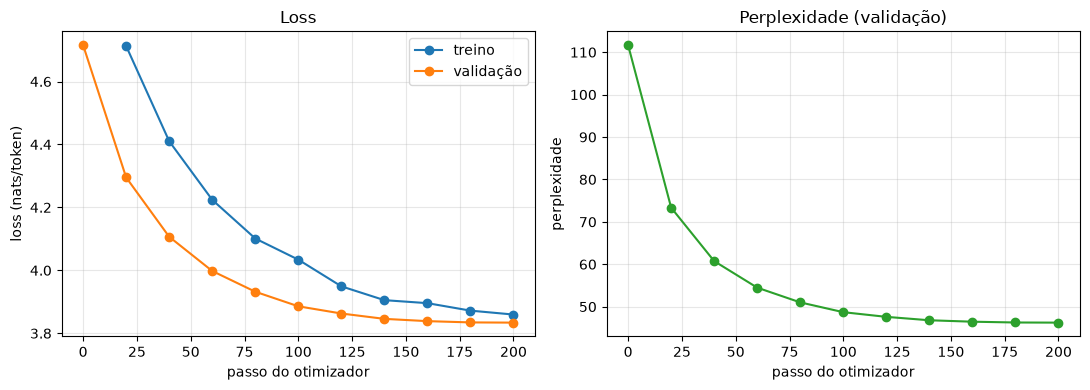

In [6]:
import pandas as pd
from machado_gpt.config import RESULTS
from machado_gpt.evaluate import plot_loss_curves

hist = pd.DataFrame(result["history"])
display(hist.round(4))
fig = plot_loss_curves(hist, RESULTS / "curvas_loss.png")

In [7]:
meta = result["meta"]
print(f"Tempo de treino     : {meta['train_time_s'] / 60:.1f} min")
print(f"Pico de memória GPU : {meta['peak_gpu_mem_gb']} GB")
print(f"Perplexidade (val)  : {meta['baseline_val_ppl']:.1f} (original) -> {meta['best_val_ppl']:.1f} (fine-tuned)")

Tempo de treino     : 5.1 min
Pico de memória GPU : 2.83 GB
Perplexidade (val)  : 111.6 (original) -> 46.2 (fine-tuned)


## 4. Avaliação experimental

In [8]:
from machado_gpt.config import TUNED_DIR
from machado_gpt.generate import load_model
from machado_gpt.evaluate import (compare_models, summarize, perplexity_table, rebuild_splits,
                                  load_corpus_vocab, temperature_sweep)

base = load_model(BASE_MODEL)
tuned = load_model(str(TUNED_DIR))
models = {"GPT-2 PT (original)": base, "GPT-2 PT + Machado": tuned}
vocab = load_corpus_vocab()

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: pierreguillou/gpt2-small-portuguese
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

## 5. Demonstração

Interface com um campo de prompt e os dois modelos lado a lado (mesma seed e mesmos parâmetros). Antes de abrir, libere a memória da GPU dos modelos de avaliação.

In [9]:
import gc
del base, tuned, models
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [10]:
from machado_gpt.app import build_demo

demo = build_demo()
demo.launch(inline=True)   # para abrir em outra aba do navegador: demo.launch(inline=False)

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: pierreguillou/gpt2-small-portuguese
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
